In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from scipy.spatial.transform import Rotation
import scanpy as sc

# ==========================================
# 0. Environment configuration and path settings
# ==========================================

batch = 'nS06'
img_path = '../fluorescence/nS06/3.jpg'

# Load the DAPI fluorescence image as background (for four-panel size reference)
img_tot = cv2.imread(img_path)
if img_tot is None:
    raise FileNotFoundError(f"Cannot find image: {img_path}")

# ==========================================
# 1. Core rigid alignment function
# ==========================================
def estimate_similarity_transform(src_points, dst_points):
    src = np.asarray(src_points, dtype=np.float64)
    dst = np.asarray(dst_points, dtype=np.float64)
    if src.shape != dst.shape or src.shape[1] != 2:
        raise ValueError("Input point sets must have consistent shapes of (N, 2)")
    mean_src = np.mean(src, axis=0)
    mean_dst = np.mean(dst, axis=0)
    src_centered = src - mean_src
    dst_centered = dst - mean_dst
    var_src = np.sum(src_centered ** 2)
    if var_src < 1e-12:
        raise ValueError("Source point set is degenerate (all points coincide), cannot compute transform")
    H = src_centered.T @ dst_centered
    U, S, Vt = np.linalg.svd(H)
    R = Vt.T @ U.T
    if np.linalg.det(R) < 0:
        Vt[-1, :] *= -1
        R = Vt.T @ U.T
    s = np.sum(S) / var_src
    t = mean_dst - s * (R @ mean_src)
    return s, R, t

def parse_points(data_str):
    blocks = data_str.strip().split('#')
    src_pts, dst_pts = [], []
    for line in blocks[1].strip().split('\n'):
        line = line.strip()
        if not line or 'x' in line: continue
        parts = line.split(',')
        src_pts.append([float(parts[1]), float(parts[2])])
    for line in blocks[2].strip().split('\n'):
        line = line.strip()
        if not line or 'x' in line: continue
        parts = line.split(',')
        dst_pts.append([float(parts[1]), float(parts[2])])
    return np.array(src_pts), np.array(dst_pts)

# ==========================================
# 2. Perform rigid alignment transform
# ==========================================
src_points = [[11620.41506498,  8006.57763281],
        [12626.35210902, 12962.89260837],
        [11384.38597218,  2624.4600496 ],
        [ 2167.25953375,  9013.60970385],
        [10309.42701214,  2381.71633953],
        [ 3111.56660442,  7225.0963004 ],
        [ 9257.3354129 ,  5383.11185076]]
dst_points = [[826.81487479, 605.01053253],
        [910.47476365, 931.56626615],
        [792.21286343, 242.31893431],
        [186.11550762, 712.87315734],
        [720.56856668, 253.58332066],
        [239.83956373, 578.37107574],
        [651.67624007, 443.27981253]]

s, R, t = estimate_similarity_transform(src_points, dst_points)

# Load spatial transcriptomics data
adata_HD = sc.read("../h5ad/adata_HD.h5ad")
spots = adata_HD[adata_HD.obs["batch"]=='nS06'].obsm["spatial"]
spot_types = adata_HD[adata_HD.obs["batch"]=='nS06'].obs["type"]

# Rigid transform
trans_spots = spots @ np.array([[s*R[0,0], s*R[1,0]], [s*R[0,1], s*R[1,1]]]) + np.array([t[0], t[1]])

In [2]:
# ==========================================
# 3. Image cropping and four-panel display functions
# ==========================================
def crop_rot_with_box(path, rect, highlight_rect=None):
    img = cv2.imread(path)
    if img is None: raise FileNotFoundError(f"Image not found: {path}")
    w = int(max(np.linalg.norm(rect[0]-rect[1]), np.linalg.norm(rect[3]-rect[2])))
    h = int(max(np.linalg.norm(rect[0]-rect[3]), np.linalg.norm(rect[1]-rect[2])))
    dst = np.array([[0,0], [w,0], [w,h], [0,h]], dtype=np.float32)
    M = cv2.getPerspectiveTransform(rect.astype(np.float32), dst)
    cropped_img = cv2.warpPerspective(img, M, (w, h))
    
    if highlight_rect is not None:
        pts = highlight_rect.astype(np.float32).reshape(-1, 1, 2)
        transformed_pts = cv2.perspectiveTransform(pts, M).astype(np.int32)
        cv2.polylines(cropped_img, [transformed_pts], True, (255, 255, 255), 4)
        
        pt_bottom_left = transformed_pts[3][0]
        pt_bottom_right = transformed_pts[2][0]
        center_x = int((pt_bottom_left[0] + pt_bottom_right[0]) / 2)
        center_y = int((pt_bottom_left[1] + pt_bottom_right[1]) / 2)
        arrow_width, line_thickness = 20, 4
        tip_y = h
        cv2.line(cropped_img, (center_x, center_y), (center_x, tip_y), (255, 255, 255), line_thickness)
        p1 = (center_x, tip_y)
        p2 = (center_x - arrow_width, tip_y - arrow_width)
        p3 = (center_x + arrow_width, tip_y - arrow_width)
        cv2.fillPoly(cropped_img, [np.array([p1, p2, p3], dtype=np.int32)], (255, 255, 255))
    return cv2.cvtColor(cropped_img, cv2.COLOR_BGR2RGB)

def get_rect(pts):
    pts = pts.astype(np.float32)
    box = cv2.boxPoints(cv2.minAreaRect(pts))
    y_s = box[np.argsort(box[:, 1])]
    t, b = y_s[:2][np.argsort(y_s[:2, 0])], y_s[2:][np.argsort(y_s[2:, 0])]
    return np.array([t[0], t[1], b[1], b[0]], dtype=np.float32)

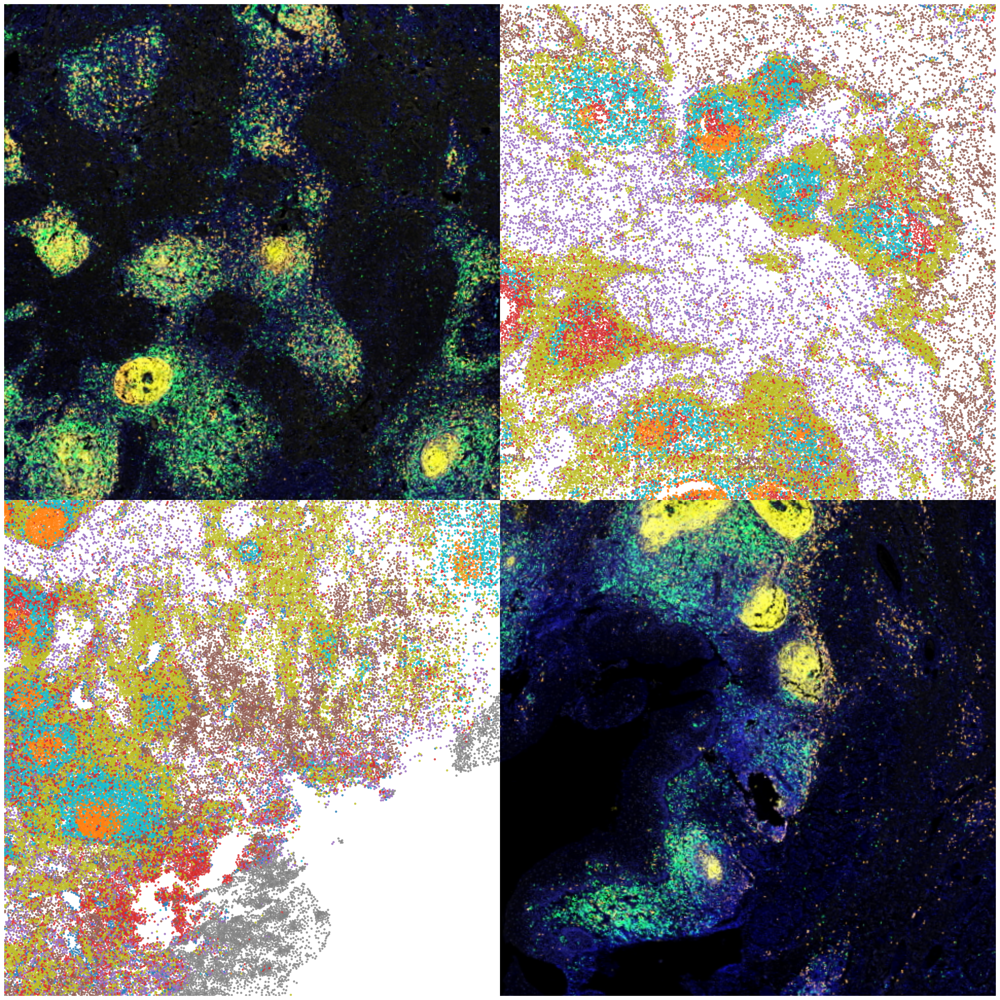

In [3]:
# ==========================================
# 4. Draw four-panel layout
# ==========================================
opacity = 0.8
r = get_rect(trans_spots)
ux, uy = (r[1]-r[0]), (r[3]-r[0])
M_mat = np.vstack([ux/np.linalg.norm(ux), uy/np.linalg.norm(uy)])

pts = (trans_spots - (r[2]+r[0])/2) @ M_mat.T
pts = np.array([[pt[0], -pt[1]] for pt in pts])

pts_up = pts[np.all(pts>=0, axis=1)]
pts_down = pts[np.all(pts<=0, axis=1)]

h_img, w_img, _ = img_tot.shape

# Use GridSpec with wspace/hspace=0 to ensure no spacing
gs = plt.GridSpec(2, 2, wspace=0, hspace=0)
fig = plt.figure(figsize=(w_img/50, h_img/50), dpi=100)

axes = [fig.add_subplot(gs[i, j]) for i in range(2) for j in range(2)]
axes = np.array(axes).reshape(2, 2)

# Define color mapping dictionary
color_mapping_dict = {
    'B cell': '#ff7f0e', 'Endothelial cell': '#1f77b4',
    'Epithelial cell': '#7f7f7f', 'Stromal cell': '#9467bd',
    'Muscle cell': '#8c564b', 'Myeloid cell': '#d62728',
    'Plasma cell': '#bcbd22', 'T cell': '#17becf'
}

# Top-left: fluorescence image
axes[0, 0].imshow(crop_rot_with_box(img_path, np.array([r[0]+(rp-r[0])/2 for rp in r])))
axes[0, 0].axis('off')

# Top-right: scatter plot (upper-right quadrant)
if len(pts_up) > 0:
    axes[0, 1].set_xlim(0, np.linalg.norm(ux)/2)
    axes[0, 1].set_ylim(0, np.linalg.norm(uy)/2)
    # Map colors using the dictionary
    colors_up = [color_mapping_dict.get(t, '#000000') for t in spot_types[np.all(pts>=0, axis=1)]]
    axes[0, 1].scatter(pts_up[:, 0], pts_up[:, 1], 
                       c=colors_up, 
                       s=15, alpha=opacity, edgecolors='none')
axes[0, 1].axis('off')

# Bottom-left: scatter plot (lower-left quadrant)
if len(pts_down) > 0:
    axes[1, 0].set_xlim(-np.linalg.norm(ux)/2, 0)
    axes[1, 0].set_ylim(-np.linalg.norm(uy)/2, 0)
    # Map colors using the dictionary
    colors_down = [color_mapping_dict.get(t, '#000000') for t in spot_types[np.all(pts<=0, axis=1)]]
    axes[1, 0].scatter(pts_down[:, 0], pts_down[:, 1], 
                       c=colors_down, 
                       s=15, alpha=opacity, edgecolors='none')
axes[1, 0].axis('off')

# Bottom-right: fluorescence image
axes[1, 1].imshow(crop_rot_with_box(img_path, np.array([r[2]-(r[2]-rp)/2 for rp in r])))
axes[1, 1].axis('off')
plt.tight_layout(pad=0)
plt.show()